# LSTM, Batchnorm & Dropout for next-hour electricity consumption forecasting

## 1. Imports, experiment settings, & output folder

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # Must precede importing keras

import io
import json
import socket
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import torch
import keras
from keras import ops
from keras.layers import Input, LSTM, Dense, BatchNormalization, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback
from keras.metrics import MeanAbsoluteError, RootMeanSquaredError, MeanAbsolutePercentageError

MODEL_TAG = "Single LSTM with Batchnorm"
SEED = 42
WINDOW_SIZE = 48
# 70% train, 15% validation, 15% test.
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
LSTM_UNITS = 64  # Number of hidden units in the only LSTM layer
DROPOUT_RATE = 0.10  # Drop 10% of final LSTM features
BATCH_SIZE = 256
EPOCHS = 100
EARLY_STOP_PATIENCE = 10
REDUCE_LEARNING_RATE_PATIENCE = 3
LEARNING_RATE = 0.001
IMPORTANCE_N = 1024
PERM_REPEATS = 3

DATA_DIR = Path("../data/")
OUTPUT_DIR = Path("lstm_research_results") / MODEL_TAG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)
print("Model:", MODEL_TAG, "| data:", DATA_DIR, "| outputs:", OUTPUT_DIR)

Model: Single LSTM with Batchnorm | data: ../data | outputs: lstm_research_results/Single LSTM with Batchnorm


## 2. Residential metadata


In [2]:
file_path = DATA_DIR / "All_Residential.txt"

with open(file_path, 'r', encoding="utf-8") as f:
    lines = f.read().splitlines() 

end = next((i for i, line in enumerate(lines) if line.strip() == "***"), None) 
table_lines = [line for line in lines[:end] if line.strip()] 
table_str = '\n'.join(table_lines) 
table_io = io.StringIO(table_str) 
df = pd.read_fwf(table_io)
metadata = df.drop([0]) 

metadata["HouseType"] = metadata["HouseType"].fillna(metadata["HouseType"].mode()[0])
metadata["Region"] = metadata["Region"].fillna(metadata["Region"].mode()[0])
metadata['House'] = metadata['House'].astype(int)


## 3. Residential hourly electricity and house metadata merge


In [3]:
energy_data = []
for i in range(1, 29):
    file_path = DATA_DIR / f'Residential_{i}.csv'

    df = pd.read_csv(file_path)
    df['date'] = pd.to_datetime(df['date'])
    df['hour'] += 1
    df['dst'] = 0
    
    gap_mask = df['hour'].diff() == 2
    gap_mask &= df['date'].dt.month == 3
    gap_indices = list(np.where(gap_mask==True)[0])  

    repeat_mask = df['hour'].diff() == 0
    repeat_mask &= df['date'].dt.month == 11
    repeat_indices = list(np.where(repeat_mask==True)[0]) 

    if (len(repeat_indices) == 1) and (len(gap_indices) == 0):
        gap_indices.insert(0,0) 

    if (len(gap_indices) == 1) and (len(repeat_indices) == 0):
        repeat_indices.append(len(df)) 

    if repeat_indices and gap_indices and repeat_indices[0] < gap_indices[0]:
        gap_indices.insert(0,0) 

    if repeat_indices and gap_indices and repeat_indices[-1] < gap_indices[-1]:
        repeat_indices.append(len(df)) 

    for start, stop in zip(gap_indices, repeat_indices): 
        df.loc[start:stop-1, 'hour'] -= 1 
        df.loc[start:stop-1, 'dst'] = 1

    zero_mask = df['hour'] == 0
    df.loc[zero_mask, 'hour'] = 24 
    df.loc[zero_mask, 'date'] -= pd.Timedelta(days=1) 

    df = df.drop_duplicates()

    df['datetime'] = pd.to_datetime(df['date'])+pd.to_timedelta(df['hour']-1, unit='h') 
    df = df.set_index('datetime') 
    df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq='h')) 
    df['date'] = df.index.strftime("%Y-%m-%d") 
    df['hour'] = df.index.hour+1 
    df = df.reset_index(drop=True)

    df['kWh_missing'] = df['energy_kWh'].isna().astype(int)
    column_list = ['energy_kWh']

    for column in column_list:
        selected_energy_feature = df[column]

        energy_feature = (selected_energy_feature.shift(1) + selected_energy_feature.shift(-1)) / 2
        energy_feature = energy_feature.fillna((selected_energy_feature.shift(24) + selected_energy_feature.shift(-24)) / 2)
        energy_feature = energy_feature.fillna(selected_energy_feature.shift(24))
        energy_feature = energy_feature.fillna(selected_energy_feature.shift(-24))

        df[column] = selected_energy_feature.fillna(energy_feature.round(3))

    df['House'] = i
    df['date'] = pd.to_datetime(df['date'])

    energy_data.append(df)

energy_data = pd.concat(energy_data, ignore_index=True)
energy_data['House'] = energy_data['House'].astype(int)
energy_data.loc[energy_data['energy_kWh']==0,'energy_kWh'] = energy_data[energy_data['energy_kWh'] > 0]['energy_kWh'].min()

merged_residential_data = pd.merge(energy_data, metadata, on='House', how='left')


## 4. Weather records


In [4]:
weather_yvr = pd.read_csv(DATA_DIR / "Weather_YVR.csv")

weather_yvr['datetime'] = pd.to_datetime(weather_yvr['date'])+pd.to_timedelta(weather_yvr['hour']-1, unit='h') 
weather_yvr = weather_yvr.set_index('datetime') 
weather_yvr = weather_yvr.reindex(pd.date_range(weather_yvr.index.min(), weather_yvr.index.max(), freq='h')) 
weather_yvr['date'] = weather_yvr.index.strftime("%Y-%m-%d") 
weather_yvr['hour'] = weather_yvr.index.hour+1 
weather_yvr = weather_yvr.reset_index(drop=True)
weather_yvr['Region']='YVR'

weather_yvr['temp_missing'] = weather_yvr['temperature'].isna().astype(int)
weather_yvr['humid_missing'] = weather_yvr['humidity'].isna().astype(int)
weather_yvr['press_missing'] = weather_yvr['pressure'].isna().astype(int)

column_list = ['temperature', 'humidity', 'pressure']

for column in column_list:
    selected_weather_feature = weather_yvr[column]

    weather_feature = (selected_weather_feature.shift(1) + selected_weather_feature.shift(-1)) / 2
    weather_feature = weather_feature.fillna((selected_weather_feature.shift(24) + selected_weather_feature.shift(-24)) / 2)
    weather_feature = weather_feature.fillna(selected_weather_feature)
    weather_feature = weather_feature.fillna(selected_weather_feature.shift(-24))

    weather_yvr[column] = selected_weather_feature.fillna(weather_feature.round(2))

weather_yvr['weather_missing'] = weather_yvr['weather'].isna().astype(int)
weather_yvr['weather'] = weather_yvr['weather'].ffill() 

weather_wyj = pd.read_csv(DATA_DIR / "Weather_WYJ.csv")

weather_wyj['datetime'] = pd.to_datetime(weather_wyj['date'])+pd.to_timedelta(weather_wyj['hour']-1, unit='h') 
weather_wyj = weather_wyj.set_index('datetime') 
weather_wyj = weather_wyj.reindex(pd.date_range(weather_wyj.index.min(), weather_wyj.index.max(), freq='h')) 
weather_wyj['date'] = weather_wyj.index.strftime("%Y-%m-%d") 
weather_wyj['hour'] = weather_wyj.index.hour+1 
weather_wyj = weather_wyj.reset_index(drop=True)
weather_wyj['Region']='WYJ'

weather_wyj['temp_missing'] = weather_wyj['temperature'].isna().astype(int)
weather_wyj['humid_missing'] = weather_wyj['humidity'].isna().astype(int)
weather_wyj['press_missing'] = weather_wyj['pressure'].isna().astype(int)

column_list = ['temperature', 'humidity', 'pressure']

for column in column_list:
    selected_weather_feature = weather_wyj[column]

    weather_feature = (selected_weather_feature.shift(1) + selected_weather_feature.shift(-1)) / 2
    weather_feature = weather_feature.fillna((selected_weather_feature.shift(24) + selected_weather_feature.shift(-24)) / 2)
    weather_feature = weather_feature.fillna(selected_weather_feature)
    weather_feature = weather_feature.fillna(selected_weather_feature.shift(-24))

    weather_wyj[column] = selected_weather_feature.fillna(weather_feature.round(2))

weather_wyj['weather_missing'] = weather_wyj['weather'].isna().astype(int)
weather_wyj['weather'] = weather_wyj['weather'].ffill() 

lookup = weather_yvr.set_index(['date', 'hour'])['weather']
weather_wyj['weather'] = pd.Series(list(zip(weather_wyj['date'], weather_wyj['hour']))).map(lookup)
weather_data = pd.concat([weather_wyj, weather_yvr])


## 5. Weather merge and input feature encoding


In [5]:
weather_for_merge = weather_data[["date", "hour", "Region", "temperature", "weather"]].copy()
weather_for_merge["date"] = pd.to_datetime(weather_for_merge["date"])
weather_for_merge["hour"] = pd.to_numeric(weather_for_merge["hour"], errors="coerce")
weather_for_merge["temperature"] = pd.to_numeric(weather_for_merge["temperature"], errors="coerce")
weather_for_merge = weather_for_merge.drop_duplicates(["date", "hour", "Region"])

# For WYJ dates still missing temperature. After interpolation, use YVR temperature for the
# matching date/hour as a fallback. Separately, the weather preprocessing above substitutes
# YVR weather descriptions for WYJ weather descriptions.
yvr_lookup = weather_for_merge.loc[
    weather_for_merge["Region"].eq("YVR"), ["date", "hour", "temperature"]
].rename(columns={"temperature": "yvr_temperature_fallback"})
weather_for_merge = weather_for_merge.merge(
    yvr_lookup, on=["date", "hour"], how="left", validate="many_to_one"
)
need_fallback = weather_for_merge["Region"].eq("WYJ") & weather_for_merge["temperature"].isna()
print("WYJ rows with missing temperature before YVR fallback:", int(need_fallback.sum()))
weather_for_merge.loc[need_fallback, "temperature"] = weather_for_merge.loc[
    need_fallback, "yvr_temperature_fallback"
]
weather_for_merge = weather_for_merge.drop(columns="yvr_temperature_fallback")

df = merged_residential_data.copy()
df["date"] = pd.to_datetime(df["date"])
df["hour"] = pd.to_numeric(df["hour"], errors="coerce")
df = df.merge(weather_for_merge, on=["date", "hour", "Region"], how="left", validate="many_to_one")
df = df.sort_values(["House", "date", "hour"]).reset_index(drop=True) # Sort each house's record for training
df["weather"] = df["weather"].astype("string").fillna("Unknown")

train_parts = []
for _, house in df.groupby("House", sort=False):
    train_parts.append(house.iloc[:int(len(house) * TRAIN_FRACTION)])
train_rows = pd.concat(train_parts, ignore_index=True)
weather_categories = sorted(train_rows["weather"].dropna().unique().tolist())
if "Unknown" not in weather_categories:
    weather_categories.append("Unknown")

df.loc[~df["weather"].isin(weather_categories), "weather"] = "Unknown"
weather_encoded = pd.get_dummies(
    pd.Categorical(df["weather"], categories=weather_categories),
    prefix="weather", dtype=np.float32
)
WEATHER_COLUMNS = weather_encoded.columns.tolist()
df = pd.concat([df, weather_encoded], axis=1)

# HouseType is required in the residential metadata.
df["HouseType"] = df["HouseType"].astype("string").fillna("Unknown")
train_house_types = sorted(train_rows["HouseType"].astype("string").fillna("Unknown").unique().tolist())
if "Unknown" not in train_house_types:
    train_house_types.append("Unknown")
df.loc[~df["HouseType"].isin(train_house_types), "HouseType"] = "Unknown"
house_encoded = pd.get_dummies(
    pd.Categorical(df["HouseType"], categories=train_house_types),
    prefix="house_type", dtype=np.float32
)
HOUSE_COLUMNS = house_encoded.columns.tolist()
df = pd.concat([df, house_encoded], axis=1)

FEATURE_COLUMNS = ["energy_kWh", "temperature"] + WEATHER_COLUMNS + HOUSE_COLUMNS
FEATURE_GROUPS = {
    "Energy history": ["energy_kWh"],
    "Temperature": ["temperature"],
    "Weather condition": WEATHER_COLUMNS,
    "House type": HOUSE_COLUMNS,
}
N_FEATURES = len(FEATURE_COLUMNS)
print("Rows:", len(df), "Houses:", df["House"].nunique(), "Features:", N_FEATURES)
print("Grouped input feature counts:", {k: len(v) for k,v in FEATURE_GROUPS.items()})
print("Rows with missing temperature:", int(df["temperature"].isna().sum()))
print("Weather categories:", weather_categories)


WYJ rows with missing temperature before YVR fallback: 14
Rows: 616080 Houses: 28 Features: 36
Grouped input feature counts: {'Energy history': 1, 'Temperature': 1, 'Weather condition': 26, 'House type': 8}
Rows with missing temperature: 500
Weather categories: ['Clear', 'Cloudy', 'Drizzle', 'Fog', 'Freezing Drizzle', 'Freezing Fog', 'Freezing Rain', 'Haze', 'Heavy Rain', 'Heavy Rain Showers', 'Heavy Snow', 'Ice Pellets', 'Mainly Clear', 'Moderate Drizzle', 'Moderate Rain', 'Moderate Rain Showers', 'Moderate Snow', 'Mostly Cloudy', 'Rain', 'Rain Showers', 'Smoke', 'Snow', 'Snow Grains', 'Snow Showers', 'Thunderstorms', 'Unknown']


## 6. Train/validation/test split

In [6]:
# Store the numerical input features for all houses. So each row contains the features for a specific house at a specific hour
# Each row has the different features (energy consumption, temperature, weather conditions, and house type)
raw_values = df[FEATURE_COLUMNS].to_numpy(dtype=np.float32, copy=True)
energy_index = FEATURE_COLUMNS.index('energy_kWh')


index_parts = {'train': [], 'val': [], 'test': []}
start = 0
for house_id, house in df.groupby('House', sort=False):
    n = len(house)
    # Getting the last index of train and val set
    train_end = int(n * TRAIN_FRACTION)
    val_end = int(n * (TRAIN_FRACTION + VAL_FRACTION))
    if train_end <= WINDOW_SIZE or not (train_end < val_end < n):
        start += n
        continue

    house_values = raw_values[start:start+n] # Extract only the current house's numerical feature values.
    invalid = ~np.isfinite(house_values).all(axis=1) # Find rows with missing values.
    cumulative = np.r_[0, np.cumsum(invalid, dtype=np.int64)] # Count invalid rows.
    target_positions = np.arange(WINDOW_SIZE, n) # Candidate target positions with 24 historical hours available.

    # Checks whether the previous 24 hours of input data contain any missing or invalid values
    # Also checks whether the next-hour electricity consumption is a valid number.
    good = ((cumulative[target_positions] - cumulative[target_positions - WINDOW_SIZE]) == 0) & np.isfinite(house_values[target_positions, energy_index])
    target_positions = target_positions[good] # Keep only target positions where good is True.

    index_parts['train'].append(start + target_positions[target_positions < train_end])
    index_parts['val'].append(start + target_positions[(target_positions >= train_end) & (target_positions < val_end)])
    index_parts['test'].append(start + target_positions[target_positions >= val_end])

    start += n

# Combine the valid target positions collected from all houses 
# into one NumPy array for each dataset split (train, val, test).
split_target_indices = {}
for split_name, house_arrays in index_parts.items():
    if house_arrays:
        split_target_indices[split_name] = np.concatenate(
            house_arrays
        ).astype(np.int64)
    else:
        split_target_indices[split_name] = np.empty(
            0,
            dtype=np.int64
        )

for split_name, target_indices in split_target_indices.items():
    print(f'{split_name} ({dict(train=TRAIN_FRACTION, val=VAL_FRACTION, test=TEST_FRACTION)[split_name]:.0%}): {len(target_indices):,} valid next-hour samples')
    if len(target_indices) == 0:
        raise ValueError(f'No valid windows for {split_name}; check weather coverage')

training_rows = np.zeros(len(df), dtype=bool)
start = 0
for _, house in df.groupby('House', sort=False):
    n = len(house)
    training_rows[start:start+int(n * TRAIN_FRACTION)] = True
    start += n

# Standardization (z-score): (input - training mean) / training standard deviation.
# energy_kWh and temperature are scaled independently; binary one-hot inputs stay 0/1.
# Next-hour target y remains unscaled in kWh, so forecasts and RMSE/MAE use kWh.
# Scaling helps the LSTM training converge faster and more reliably, but it does not change the final RMSE/MAE results.
INPUT_SCALERS = {}
for name in ['energy_kWh', 'temperature']:
    col = FEATURE_COLUMNS.index(name)
    observed = raw_values[training_rows & np.isfinite(raw_values[:,col]), col]
    mean = float(np.mean(observed, dtype=np.float64))
    sd = float(np.std(observed, dtype=np.float64))
    if sd < 1e-6: sd = 1.0
    INPUT_SCALERS[name] = (mean, sd)

print('Feature groups:', {name: len(cols) for name,cols in FEATURE_GROUPS.items()})
print('Raw feature matrix GiB:', round(raw_values.nbytes/1024**3, 3))
print('Training-only scalers:', INPUT_SCALERS)


train (70%): 428,131 valid next-hour samples
val (15%): 92,225 valid next-hour samples
test (15%): 91,728 valid next-hour samples
Feature groups: {'Energy history': 1, 'Temperature': 1, 'Weather condition': 26, 'House type': 8}
Raw feature matrix GiB: 0.083
Training-only scalers: {'energy_kWh': (0.849954534808858, 0.8709810683072455), 'temperature': (10.776099912917271, 6.268502355969888)}


## 7. 24-hour data windows

In [7]:
class ForecastWindows(keras.utils.PyDataset):
    """Provide 24-hour sequences for next-hour forecasting, one batch at a time."""

    def __init__(self, raw, targets, batch_size=BATCH_SIZE, shuffle=False):
        # Initialize Keras's dataset interface (one worker, no multiprocessing).
        super().__init__(workers=1, use_multiprocessing=False, max_queue_size=2)
        self.raw = raw  # Shared 2D matrix: all rows x all features (not copied here).
        self.targets = np.array(targets, dtype=np.int64, copy=True)  # Eligible target row indices.
        self.batch_size = int(batch_size)  # How many windows Keras requests at once.
        self.shuffle = shuffle  # Shuffle training SAMPLE order; never shuffle hours inside a window.
        self.rng = np.random.default_rng(SEED)  # Repeatable shuffle sequence.
        self.on_epoch_end()  # Randomize initial training order when shuffle=True.

    def __len__(self):
        # Number of batches per epoch; include the final, possibly smaller batch.
        return (len(self.targets) + self.batch_size - 1) // self.batch_size

    def __getitem__(self, i):
        """
        Get one batch of historical input windows (X)
        and their corresponding next-hour electricity targets (y).
        """
        # Indices of the next-hour targets in batch i.
        target_indices = self.targets[i * self.batch_size:(i + 1) * self.batch_size]

        # X: previous WINDOW_SIZE hours for each target -> (batch, 24, features).
        X = np.stack([self.raw[t - WINDOW_SIZE:t] for t in target_indices]).astype(np.float32)

        # y: observed electricity consumption AT the target hour (unscaled kWh).
        y = self.raw[target_indices, energy_index].astype(np.float32, copy=True)

        # Apply training-fitted Z-score normalization to historical energy and temperature.
        for colname, (mean, sd) in INPUT_SCALERS.items():
            column = FEATURE_COLUMNS.index(colname)  # Column position in X.
            X[:, :, column] = (X[:, :, column] - mean) / sd
        return X, y  # Keras receives one feature batch and its target values.

    def on_epoch_end(self):
        # Keras calls this at epoch boundaries; validation/test keep chronological order.
        if self.shuffle:
            self.rng.shuffle(self.targets)


# Create datasets ONCE, then reuse for fit(), evaluate(), and prediction.
train_ds = ForecastWindows(raw_values, split_target_indices["train"], shuffle=True)
val_ds = ForecastWindows(raw_values, split_target_indices["val"], shuffle=False)
test_ds = ForecastWindows(raw_values, split_target_indices["test"], shuffle=False)

# One batch sanity check; does not recreate the datasets.
X_batch, y_batch = train_ds[0]
print("Training batch:", X_batch.shape, "Targets:", y_batch.shape)

Training batch: (256, 48, 36) Targets: (256,)


## 8. One-layer LSTM model + Batchnorm

In [8]:
# Register the custom metric so saved Keras models can identify it.
# SMAPE is calculated for evaluation; the optimizer minimizes MSE.
@keras.saving.register_keras_serializable(package="Custom")
def smape(y_true, y_pred):
    """Symmetric absolute percentage error for each forecast (percent)."""
    yt = ops.cast(ops.reshape(y_true, (-1,)), "float32")
    yp = ops.cast(ops.reshape(y_pred, (-1,)), "float32")
    # The small denominator floor avoids division by zero near 0 kWh.
    return 200.0 * ops.abs(yt - yp) / ops.maximum(ops.abs(yt) + ops.abs(yp), 1e-7)

def build_model():
    """One LSTM layer, BatchNorm, and one output Dense layer."""
    # Input shape per example: (24 earlier hours, number of encoded features).
    inputs = Input(shape=(WINDOW_SIZE, N_FEATURES), name="input_history")

    # The LSTM summarizes the full 24-hour sequence into its last hidden state.
    # No extra LSTM, attention, residual, or hidden Dense layer. BatchNorm is added after LSTM.
    last_hidden = LSTM(
        LSTM_UNITS,
        return_sequences=False,
        kernel_initializer="glorot_uniform",
        recurrent_initializer="orthogonal",
        name="lstm_1",
    )(inputs)

    # Linear output: forecast next-hour electricity consumption directly in kWh.
    # BatchNorm: normalize the 64 learned LSTM features across each training batch.
    # At validation/prediction time, Keras uses the running training statistics.
    normalized_hidden = BatchNormalization(axis=-1, name="batch_norm")(last_hidden)

    # Apply dropout AFTER LayerNorm; active only during training, not inference.
    dropped_hidden = Dropout(DROPOUT_RATE, name="lstm_output_dropout")(normalized_hidden)

    # Forecast the next-hour energy directly in unscaled kWh.
    output = Dense(1, activation="linear", name="forecast_kwh")(dropped_hidden)

    # Join the input and forecast output into a complete Keras model.
    net = keras.Model(inputs, output, name=MODEL_TAG)
    # MSE is the training objective; other metrics are for reporting.
    net.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=[
            MeanAbsoluteError(name="mae"),
            RootMeanSquaredError(name="rmse"),
            MeanAbsolutePercentageError(name="mape"),
            smape,
        ],
    )
    return net

# Build the architecture with reproducible initial parameter values.
keras.utils.set_random_seed(SEED)
model = build_model()

# Keras PyTorch backend: place the model on the first NVIDIA GPU, if available.
if torch.cuda.is_available():
    model.to("cuda:0")

print("Compute node:", socket.gethostname(), "| GPU available:", torch.cuda.is_available())
print("Model device:", next(model.parameters()).device)
model.summary()
print("Total parameters:", model.count_params())


Compute node: ng31402 | GPU available: True
Model device: cuda:0


Model: "Single LSTM with Batchnorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_history (InputLayer)      │ (None, 48, 36)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_output_dropout (Dropout)   │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ forecast_kwh (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,177 (102.25 KB)

 Trainable params: 26,049 (101.75 KB)

 Non-trainable params: 128 (512.00 B)

Total parameters: 26177


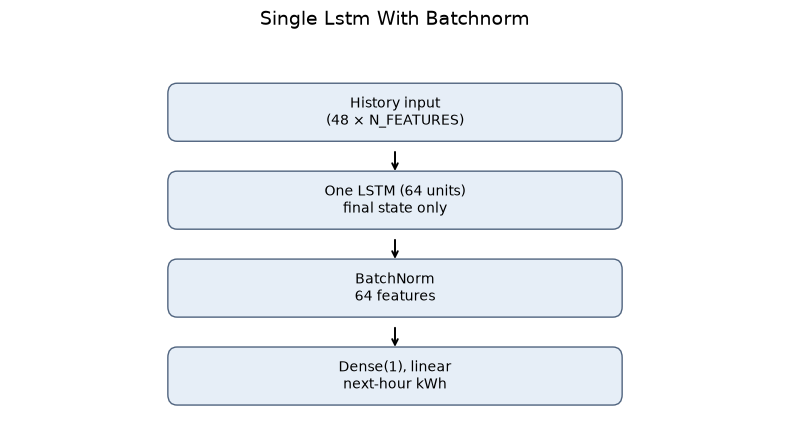

In [9]:
# Diagram shows the actual model; no architecture-switch flags.
stages = ['History input\n(48 × N_FEATURES)', 'One LSTM (64 units)\nfinal state only', 'BatchNorm\n64 features', 'Dense(1), linear\nnext-hour kWh']
fig, ax = plt.subplots(figsize=(8, max(4, 0.85 * len(stages) + 1)))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(stages) + 0.4)
ax.axis("off")
for j, text in enumerate(stages):
    y = len(stages) - j - 0.5
    ax.add_patch(FancyBboxPatch(
        (2.1, y - 0.28), 5.8, 0.56,
        boxstyle="round,pad=0.05,rounding_size=.12",
        facecolor="#e6eef7", edgecolor="#50647f",
    ))
    ax.text(5, y, text, ha="center", va="center", fontsize=10)
    if j:
        ax.annotate("", xy=(5, y + 0.30), xytext=(5, y + 0.58),
                    arrowprops=dict(arrowstyle="->", lw=1.4))
ax.set_title(MODEL_TAG.replace("_", " ").title(), fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "architecture.png", dpi=150)
plt.show()


## 9. Training and visible early stopping


In [10]:
class EarlyStoppingReporter(Callback):
    """Print validation-loss progress after each epoch; does NOT stop training itself."""

    def on_train_begin(self, logs=None):
        # Keras calls this once before model.fit() starts.
        # +inf ensures the first observed validation loss counts as an improvement.
        self.best_val = float("inf")
        self.wait = 0  # Number of consecutive epochs without a new best loss.

    def on_epoch_end(self, epoch, logs=None):
        # Keras calls this after each epoch, when validation metrics are available.
        # logs is a dictionary like {'loss': ..., 'val_loss': ..., 'mae': ...}.
        val_loss = (logs or {}).get("val_loss")
        if val_loss is None:
            return  # Nothing to report if this epoch has no validation loss.

        # A smaller validation MSE is better. 1e-12 ignores negligible float noise.
        if val_loss < self.best_val - 1e-12:
            self.best_val = float(val_loss)  # Save best validation loss seen by the reporter.
            self.wait = 0  # Improvement resets the counter.
        else:
            self.wait += 1  # No new best value; increase the wait counter.

        # Epoch is zero-based internally, so add 1 for human-readable numbering.
        # wait=3/6 means three consecutive epochs without improvement (patience=6).
        print(
            f"[EarlyStop] epoch={epoch + 1} val_loss={val_loss:.6f} "
            f"best={self.best_val:.6f} wait={self.wait}/{EARLY_STOP_PATIENCE}"
        )


# Reduce learning rate when validation loss stops improving.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=REDUCE_LEARNING_RATE_PATIENCE,
    min_lr=1e-6,
    verbose=1,
)

# Stop training if validation loss does not improve.
# Restore the weights from the best validation epoch.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True,
    verbose=1,
)

# The built-in callback stops training; our reporter only shows the progress.
# Both run after every epoch. The reporter's displayed wait is an independent
# approximation of Keras's internal counter (it uses a 1e-12 comparison tolerance).
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        reduce_lr,
        early_stopping,
        EarlyStoppingReporter()
    ],
    verbose=2,
)

# Save best-restored model weights, complete per-epoch history, and run summary.
model.save(OUTPUT_DIR / f"{MODEL_TAG}.keras")
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / "training_history.csv", index=False)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(
    f"Early stopping summary: trained={len(history.history['loss'])} epochs, "
    f"best_epoch={best_epoch}, best_val_MSE={min(history.history['val_loss']):.6f}"
)
with open(OUTPUT_DIR / "training_summary.json", "w") as f:
    json.dump(
        {
            "model": MODEL_TAG,
            "seed": SEED,
            "best_epoch": best_epoch,
            "best_val_mse": float(min(history.history["val_loss"])),
            "epochs_ran": len(history.history["loss"]),
            "early_stopped": len(history.history["loss"]) < EPOCHS,
        },
        f,
        indent=2,
    )


Epoch 1/100


/home/punrong/load-forecasting/load-forecasting-env/lib/python3.11/site-packages/keras/src/backend/torch/rnn.py:651: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /tmp/build_wheels_tmp.103000/python-3.11/torch/aten/src/ATen/native/cudnn/RNN.cpp:1481.)
  outputs, (h_n, c_n) = torch._VF.lstm(


[EarlyStop] epoch=1 val_loss=0.262530 best=0.262530 wait=0/10
1673/1673 - 139s - 83ms/step - loss: 0.3741 - mae: 0.3724 - mape: 74.7993 - rmse: 0.6116 - smape: 54.0548 - val_loss: 0.2625 - val_mae: 0.2749 - val_mape: 44.2210 - val_rmse: 0.5124 - val_smape: 37.9367 - learning_rate: 0.0010
Epoch 2/100
[EarlyStop] epoch=2 val_loss=0.248862 best=0.248862 wait=0/10
1673/1673 - 120s - 72ms/step - loss: 0.2954 - mae: 0.3064 - mape: 52.8974 - rmse: 0.5435 - smape: 39.0540 - val_loss: 0.2489 - val_mae: 0.2867 - val_mape: 54.7661 - val_rmse: 0.4989 - val_smape: 39.0737 - learning_rate: 0.0010
Epoch 3/100
[EarlyStop] epoch=3 val_loss=0.249275 best=0.248862 wait=1/10
1673/1673 - 101s - 61ms/step - loss: 0.2815 - mae: 0.2977 - mape: 50.5273 - rmse: 0.5305 - smape: 37.4672 - val_loss: 0.2493 - val_mae: 0.3020 - val_mape: 60.9142 - val_rmse: 0.4993 - val_smape: 42.1009 - learning_rate: 0.0010
Epoch 4/100
[EarlyStop] epoch=4 val_loss=0.240265 best=0.240265 wait=0/10
1673/1673 - 106s - 63ms/step - loss

## 10. Validation and held-out test evaluation


In [11]:
val_metrics = model.evaluate(val_ds, return_dict=True, verbose=0)
test_metrics = model.evaluate(test_ds, return_dict=True, verbose=0)
result_row = {"model": MODEL_TAG, "seed": SEED, "n_features": N_FEATURES,
              "validation_mse": float(val_metrics["loss"]),
              **{f"test_{k}": float(v) for k, v in test_metrics.items()}}
pd.DataFrame([result_row]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
print(pd.DataFrame([result_row]).T.to_string(header=False))


/home/punrong/load-forecasting/load-forecasting-env/lib/python3.11/site-packages/keras/src/backend/torch/rnn.py:651: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /tmp/build_wheels_tmp.103000/python-3.11/torch/aten/src/ATen/native/cudnn/RNN.cpp:1481.)
  outputs, (h_n, c_n) = torch._VF.lstm(


model           Single LSTM with Batchnorm
seed                                    42
n_features                              36
validation_mse                     0.22744
test_loss                         0.334859
test_mae                          0.306301
test_mape                        43.475842
test_rmse                          0.57867
test_smape                       32.423939


## 11. Loss curves and forecast plots


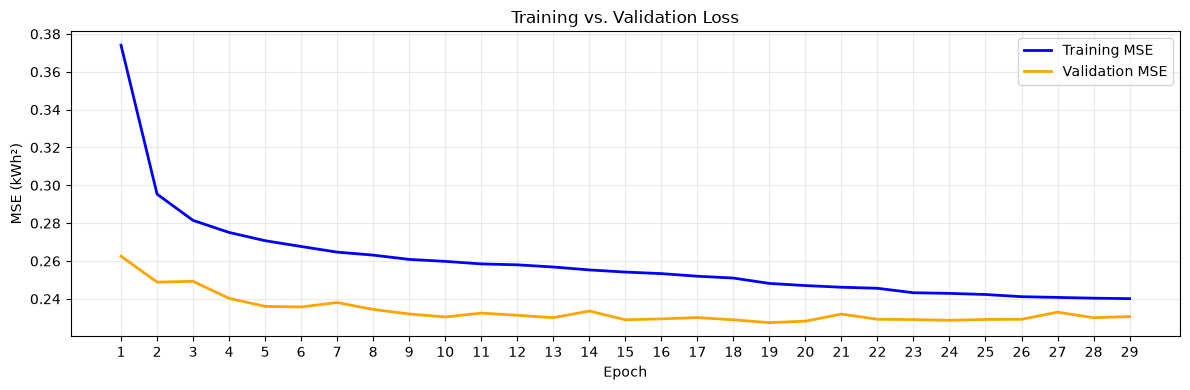

/home/punrong/load-forecasting/load-forecasting-env/lib/python3.11/site-packages/keras/src/backend/torch/rnn.py:651: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /tmp/build_wheels_tmp.103000/python-3.11/torch/aten/src/ATen/native/cudnn/RNN.cpp:1481.)
  outputs, (h_n, c_n) = torch._VF.lstm(


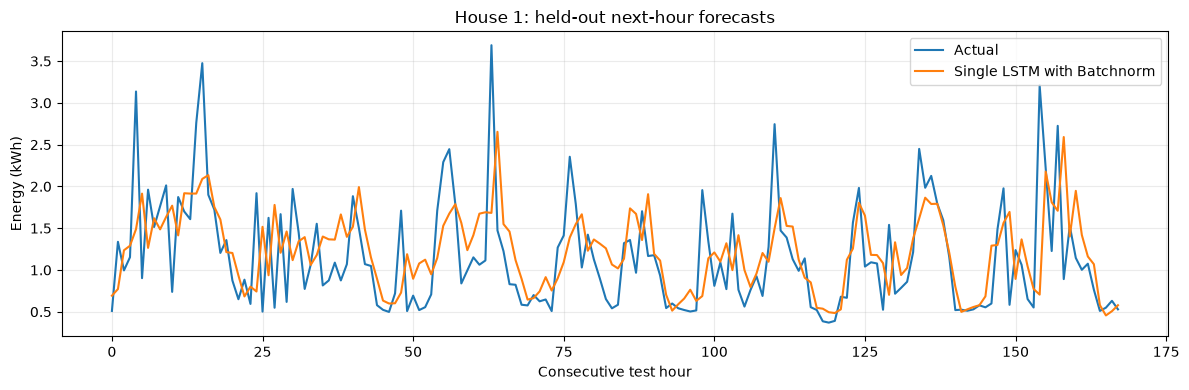

In [12]:
# Plot training and validation MSE in the same figure.
fig, ax = plt.subplots(figsize=(12, 4))

epochs = np.arange(1, len(history.history["loss"]) + 1)

ax.plot(
    epochs,
    history.history["loss"],
    label="Training MSE",
    color="blue",
    linewidth=2
)

ax.plot(
    epochs,
    history.history["val_loss"],
    label="Validation MSE",
    color="orange",
    linewidth=2
)

ax.set(
    xlabel="Epoch",
    ylabel="MSE (kWh²)",
    title="Training vs. Validation Loss"
)
ax.set_xticks(epochs)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loss.png", dpi=150)
plt.show()


def prepared_windows(target_rows):
    X = np.stack([
        raw_values[t-WINDOW_SIZE:t]
        for t in target_rows
    ]).astype(np.float32)

    for col_name, (mu, sd) in INPUT_SCALERS.items():
        j = FEATURE_COLUMNS.index(col_name)
        X[:, :, j] = (X[:, :, j] - mu) / sd

    return X


# Show a contiguous test segment from the first house.
ix = split_target_indices["test"]
first_house = df.iloc[ix[0]]["House"]

segment_ix = ix[
    df.iloc[ix]["House"].to_numpy() == first_house
][:168]

actual = raw_values[segment_ix, energy_index]

predicted = model.predict(
    prepared_windows(segment_ix),
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(actual, label="Actual")
ax.plot(predicted, label=MODEL_TAG)

ax.set(
    xlabel="Consecutive test hour",
    ylabel="Energy (kWh)",
    title=f"House {first_house}: held-out next-hour forecasts"
)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "prediction.png", dpi=150)
plt.show()

## 12. Grouped and individual permutation importance


    Feature group  Delta MSE       SD  Columns
   Energy history   1.129200 0.020642        1
       House type   0.130202 0.007517        8
      Temperature   0.010442 0.010029        1
Weather condition   0.000693 0.013267       26


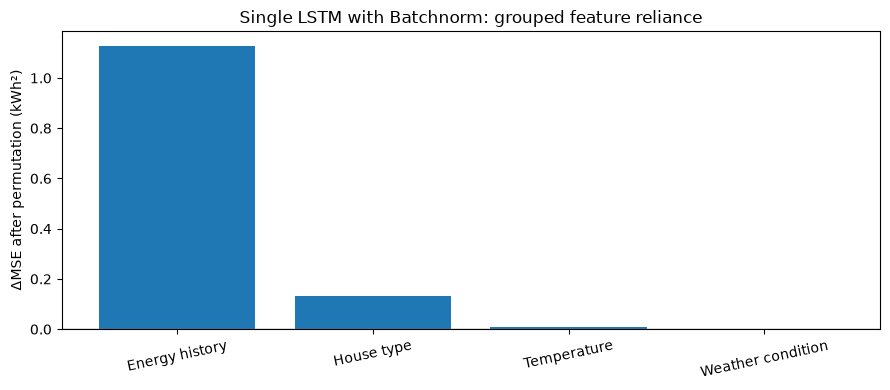

/home/punrong/load-forecasting/load-forecasting-env/lib/python3.11/site-packages/keras/src/backend/torch/rnn.py:651: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /tmp/build_wheels_tmp.103000/python-3.11/torch/aten/src/ATen/native/cudnn/RNN.cpp:1481.)
  outputs, (h_n, c_n) = torch._VF.lstm(


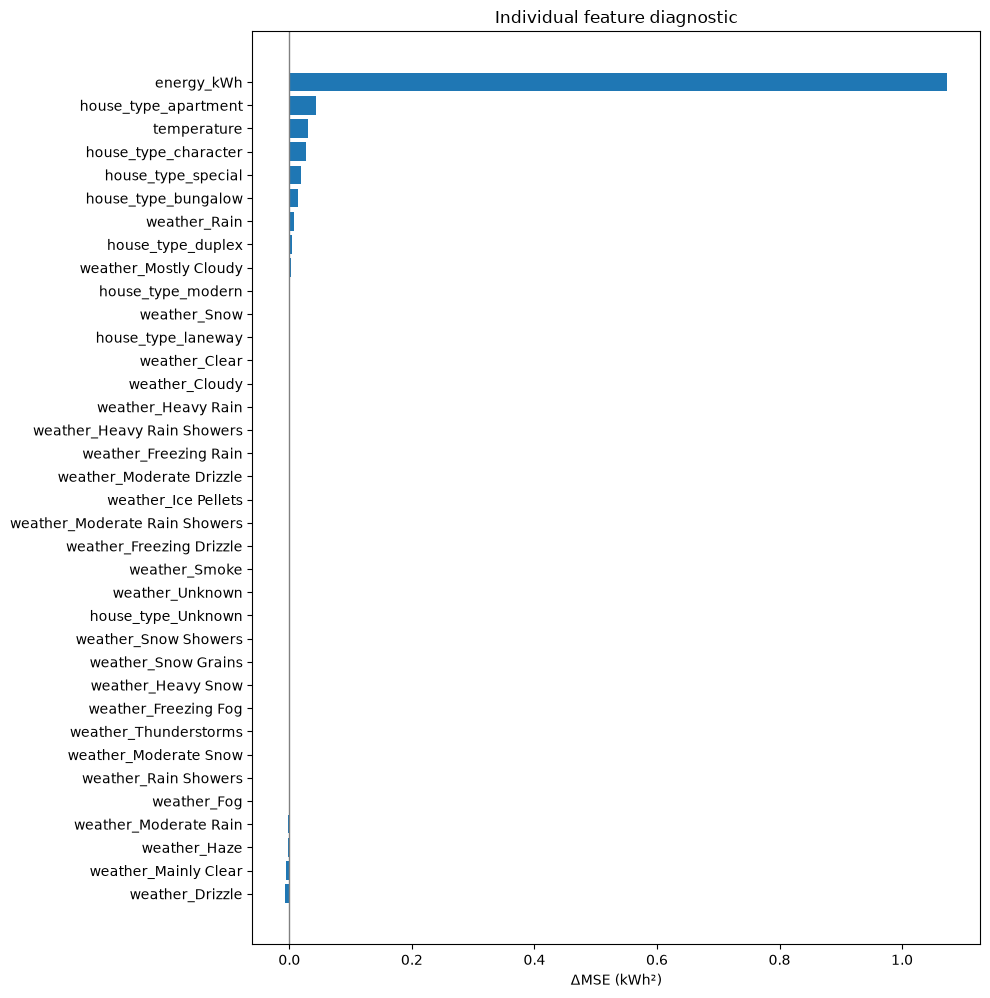

In [13]:
rng_imp = np.random.default_rng(SEED + 8)
selected = np.sort(rng_imp.choice(split_target_indices["test"], size=min(IMPORTANCE_N, len(split_target_indices["test"])), replace=False))
X_imp = prepared_windows(selected)
y_imp = raw_values[selected, energy_index]

def predict_energy(X):
    return model.predict(X, batch_size=BATCH_SIZE, verbose=0).reshape(-1)

base_mse = float(np.mean((predict_energy(X_imp) - y_imp) ** 2))
def importance_one_group(columns, repeats=PERM_REPEATS):
    column_ids = [FEATURE_COLUMNS.index(c) for c in columns]
    differences = []
    for _ in range(repeats):
        p = rng_imp.permutation(len(X_imp))
        altered = X_imp.copy()
        altered[:, :, column_ids] = X_imp[p][:, :, column_ids]
        differences.append(float(np.mean((predict_energy(altered) - y_imp) ** 2) - base_mse))
    return float(np.mean(differences)), float(np.std(differences))

rows = []
for group, columns in FEATURE_GROUPS.items():
    avg, sd = importance_one_group(columns)
    rows.append({"Feature group": group, "Delta MSE": avg, "SD": sd, "Columns": len(columns)})
grouped = pd.DataFrame(rows).sort_values("Delta MSE", ascending=False)
print(grouped.to_string(index=False))
grouped.to_csv(OUTPUT_DIR / "grouped_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(grouped["Feature group"], grouped["Delta MSE"])
ax.axhline(0, color="gray", linewidth=1)
ax.set(ylabel="ΔMSE after permutation (kWh²)", title=f"{MODEL_TAG}: grouped feature reliance")
ax.tick_params(axis="x", labelrotation=12)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "grouped_importance.png", dpi=150); plt.show()

# Individual-feature importance is always evaluated.
rows = []
for feature in FEATURE_COLUMNS:
    avg, sd = importance_one_group([feature], repeats=2)
    rows.append({"Feature": feature, "Delta MSE": avg, "SD": sd})
individual = pd.DataFrame(rows).sort_values("Delta MSE", ascending=False)
individual.to_csv(OUTPUT_DIR / "individual_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(10, max(5, .28 * len(individual))))
ax.barh(individual["Feature"].iloc[::-1], individual["Delta MSE"].iloc[::-1])
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="ΔMSE (kWh²)", title="Individual feature diagnostic")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "individual_importance.png", dpi=150); plt.show()

## 13. Weather and house-type error breakdown


In [14]:
pred_imp = predict_energy(X_imp)
for field in ["weather", "HouseType"]:
    labels = df.iloc[selected][field].astype(str).to_numpy()
    counts = pd.Series(labels).value_counts()
    rows = []
    for label, n in counts.items():
        if n < 10: continue
        mask = labels == label
        rows.append({field: label, "N": int(mask.sum()),
                     "MAE_kWh": float(np.mean(np.abs(pred_imp[mask] - y_imp[mask])))})
    result = pd.DataFrame(rows)
    if not result.empty:
        result = result.sort_values("N", ascending=False)
        print("\n", field, "\n", result.head(12).to_string(index=False))
        result.to_csv(OUTPUT_DIR / f"{field}_error_breakdown.csv", index=False)



 weather 
       weather   N  MAE_kWh
       Cloudy 252 0.324197
Mostly Cloudy 211 0.291840
         Rain 198 0.290731
 Mainly Clear 195 0.343418
        Clear  82 0.301820
          Fog  36 0.379260
 Rain Showers  19 0.359263
      Drizzle  13 0.473630
Moderate Rain  10 0.183407

 HouseType 
 HouseType   N  MAE_kWh
apartment 256 0.247745
  special 201 0.340660
   modern 171 0.391668
character 167 0.288645
 bungalow 126 0.479744
   duplex  95 0.176311


/home/punrong/load-forecasting/load-forecasting-env/lib/python3.11/site-packages/keras/src/backend/torch/rnn.py:651: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /tmp/build_wheels_tmp.103000/python-3.11/torch/aten/src/ATen/native/cudnn/RNN.cpp:1481.)
  outputs, (h_n, c_n) = torch._VF.lstm(
